# Dataset and descriptive statistics II

Reproduces the figures (and headline numbers) of slide 4 of the Phase 1 research design presentation
from the **AIDev v5** dataset ([`hao-li/AIDev`](https://huggingface.co/datasets/hao-li/AIDev)):

1. Agentic PRs per month by agent
2. Repos by month of first agentic PR
3. Hours to merge / hours to close per agent (box = IQR, whiskers = p10–p90)

`all_pull_request.parquet` is 6.7 GB. It is downloaded once into the Hugging Face cache
(`~/.cache/huggingface`); only the light columns are then streamed into a slim local copy
(`data/prs_light.parquet`), so re-running the notebook is fast and memory stays low.

Repositories are identified by `repo_id` (as on the slide: ~957k repos); about 44.5k PRs have no
`repo_id` and are left out of the repo-level counts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download

HF_REPO = "hao-li/AIDev"
HF_REVISION = "v5"  # pin the release used in the presentation (cutoff 2026-03-31)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

LIGHT_PATH = DATA_DIR / "prs_light.parquet"
PR_COLUMNS = ["agent", "user", "state", "created_at", "closed_at", "merged_at", "repo_id"]

/Users/vagnersilva/Documents/masters/semester-3/Observational Studies/tu-graz-observational-studies/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Download the PR table from Hugging Face and build a slim copy

In [3]:
def to_utc_naive(s: pd.Series) -> pd.Series:
    return pd.to_datetime(s, format="ISO8601", utc=True).dt.tz_localize(None)


if LIGHT_PATH.exists():
    prs = pd.read_parquet(LIGHT_PATH)
else:
    pr_path = hf_hub_download(HF_REPO, "all_pull_request.parquet",
                              repo_type="dataset", revision=HF_REVISION)
    parts = []
    for batch in pq.ParquetFile(pr_path).iter_batches(batch_size=500_000, columns=PR_COLUMNS):
        df = batch.to_pandas()
        for col in ["created_at", "closed_at", "merged_at"]:
            df[col] = to_utc_naive(df[col])
        parts.append(df)
    prs = pd.concat(parts, ignore_index=True)
    for col in ["agent", "state", "user"]:
        prs[col] = prs[col].astype("category")
    prs["repo_id"] = prs["repo_id"].astype("Int64")
    prs.to_parquet(LIGHT_PATH, index=False)

prs["month"] = prs["created_at"].dt.to_period("M")
prs.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 7685281 entries, 0 to 7685280
Data columns (total 8 columns):
 #   Column      Dtype         
---  ------      -----         
 0   agent       category      
 1   user        category      
 2   state       category      
 3   created_at  datetime64[us]
 4   closed_at   datetime64[us]
 5   merged_at   datetime64[us]
 6   repo_id     Int64         
 7   month       period[M]     
dtypes: Int64(1), category(3), datetime64[us](3), period[M](1)
memory usage: 351.5 MB


In [4]:
print(f"PRs:     {len(prs):>10,}")
print(f"Repos:   {prs['repo_id'].nunique():>10,}  ({prs['repo_id'].isna().sum():,} PRs without repo_id)")
print(f"Authors: {prs['user'].nunique():>10,}")
print(f"Period:  {prs['created_at'].min():%Y-%m-%d} to {prs['created_at'].max():%Y-%m-%d}")

PRs:      7,685,281
Repos:      957,209  (44,547 PRs without repo_id)
Authors:    399,963
Period:  2024-12-24 to 2026-03-31


## 2. Agentic PRs per month by agent

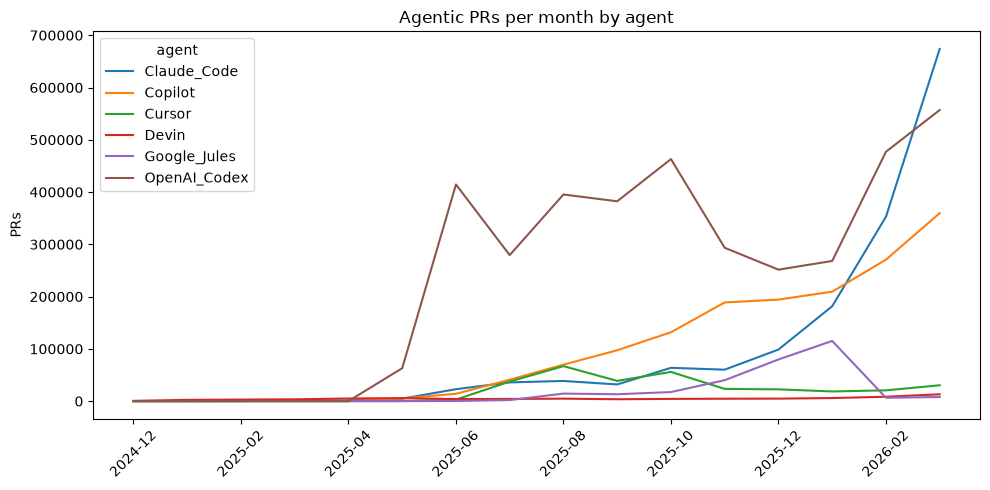

month,2026-03
agent,
Claude_Code,673792
OpenAI_Codex,556940
Copilot,359648
Cursor,30325
Devin,13115
Google_Jules,7856


In [4]:
monthly = prs.groupby(["month", "agent"], observed=True).size().unstack("agent", fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
for agent in monthly.columns:
    ax.plot(monthly.index.astype(str), monthly[agent], label=agent)
ax.set_xticks(range(0, len(monthly), 2))
ax.tick_params(axis="x", rotation=45)
ax.set_title("Agentic PRs per month by agent")
ax.set_ylabel("PRs")
ax.legend(title="agent")
plt.tight_layout()
plt.savefig(FIG_DIR / "prs_per_month_by_agent.png", dpi=150)
plt.show()

monthly.tail(1).T.sort_values(monthly.index[-1], ascending=False)

## 3. Repos by month of first agentic PR

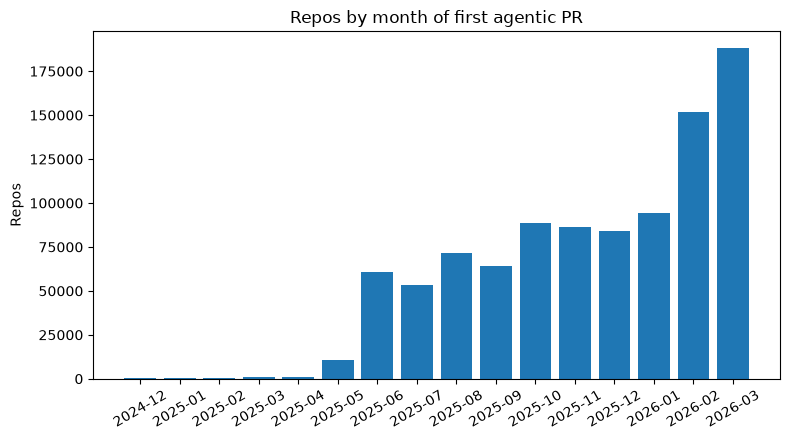

month
2025-05     10939
2026-03    188271
Freq: M, Name: count, dtype: int64

In [5]:
first_month = prs.groupby("repo_id")["month"].min()
first_counts = first_month.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(first_counts.index.astype(str), first_counts.values)
ax.set_title("Repos by month of first agentic PR")
ax.set_ylabel("Repos")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "repos_by_first_agentic_pr_month.png", dpi=150)
plt.show()

first_counts.loc[[pd.Period("2025-05", "M"), first_counts.index.max()]]

## 4. Hours to merge and hours to close per agent

* **Hours to merge**: `merged_at - created_at` for merged PRs.
* **Hours to close**: `closed_at - created_at` for all closed PRs, merged or not (as on the slide;
  the dataset's `scripts/productivity.py` instead uses only PRs closed without merging).

Boxes span the IQR, whiskers p10–p90, outliers are hidden; the y axis is symlog (linear below 1 h).

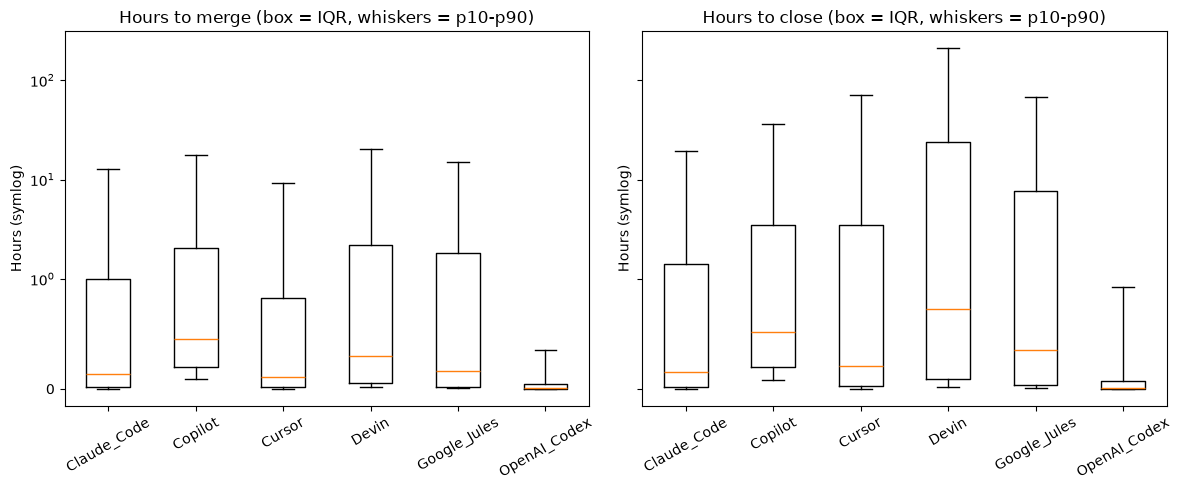

In [6]:
is_merged = prs["merged_at"].notna()
is_closed = prs["closed_at"].notna() & ~is_merged
prs["hours_to_merge"] = (prs["merged_at"] - prs["created_at"]).dt.total_seconds() / 3600
prs["hours_to_close"] = (prs["closed_at"] - prs["created_at"]).dt.total_seconds() / 3600

agents = sorted(prs["agent"].cat.categories)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (col, mask, label) in zip(axes, [("hours_to_merge", is_merged, "Hours to merge"),
                                          ("hours_to_close", prs["closed_at"].notna(), "Hours to close")]):
    data = [prs.loc[mask & (prs["agent"] == a), col].dropna() for a in agents]
    ax.boxplot(data, tick_labels=agents, whis=(10, 90), showfliers=False)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_title(f"{label} (box = IQR, whiskers = p10-p90)")
    ax.set_ylabel("Hours (symlog)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "hours_to_merge_and_close.png", dpi=150)
plt.show()

## 5. Headline numbers on the slide

In [7]:
# Concentration: share of PRs by the top 1% of authors
per_user = prs["user"].value_counts()
top1 = per_user.head(max(1, int(len(per_user) * 0.01))).sum() / per_user.sum()

# Breadth: share of repos that only ever used one agent
agents_per_repo = prs.groupby("repo_id")["agent"].nunique()

print(f"Top 1% of users produce {top1:.1%} of PRs")
print(f"Repos using a single agent: {(agents_per_repo == 1).mean():.1%}")

pd.DataFrame({
    "PRs": prs.groupby("agent", observed=True).size(),
    "merge rate": is_merged.groupby(prs["agent"], observed=True).mean(),
    "merge rate (among resolved)": is_merged.groupby(prs["agent"], observed=True).sum()
        / (is_merged | is_closed).groupby(prs["agent"], observed=True).sum(),
    "median hours to merge": prs.loc[is_merged].groupby("agent", observed=True)["hours_to_merge"].median(),
    "median minutes to merge": prs.loc[is_merged].groupby("agent", observed=True)["hours_to_merge"].median() * 60,
}).round(3)

Top 1% of users produce 54.5% of PRs
Repos using a single agent: 95.3%


,PRs,merge rate,merge rate (among resolved),median hours to merge,median minutes to merge
agent,,,,,
Claude_Code,1567100,0.880,0.918,0.137,8.200
Copilot,1581924,0.699,0.815,0.458,27.483
Cursor,317453,0.574,0.801,0.115,6.883
Devin,77791,0.596,0.719,0.299,17.917
Google_Jules,296411,0.634,0.802,0.164,9.850
OpenAI_Codex,3844602,0.862,0.930,0.011,0.633
